<a href="https://colab.research.google.com/github/tanu100/DeepLearning/blob/main/Pytorch/AutoGrad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

In [ ]:
if torch.cuda.is_available():
  print('yes')
else:
  print("no")

no


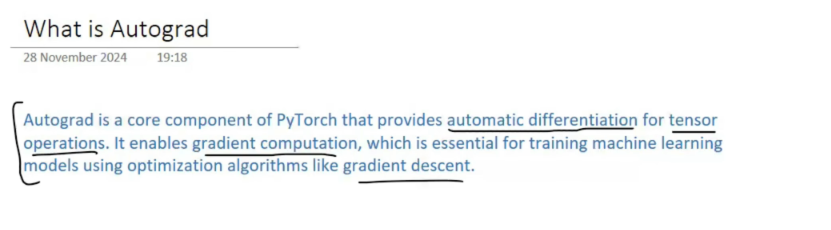

In [ ]:
x= torch.tensor(3.0 , requires_grad=True)

y = x ** 2

print(y)

tensor(9., grad_fn=<PowBackward0>)


In [ ]:
y.backward()

print(x.grad)

tensor(6.)


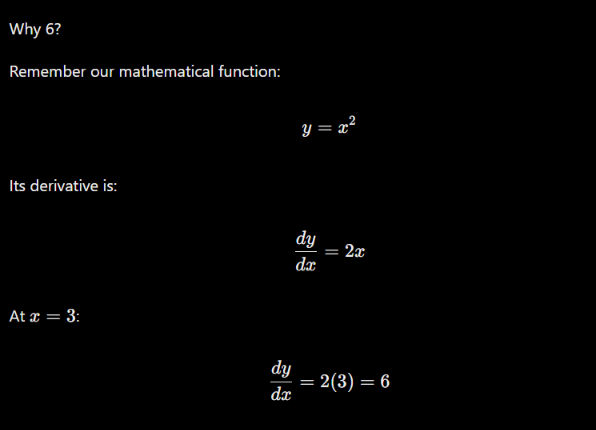

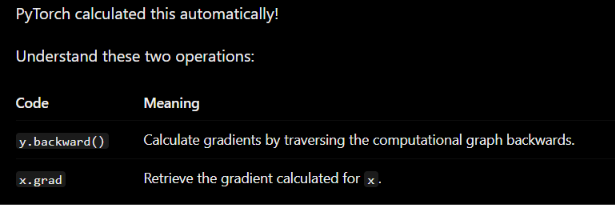

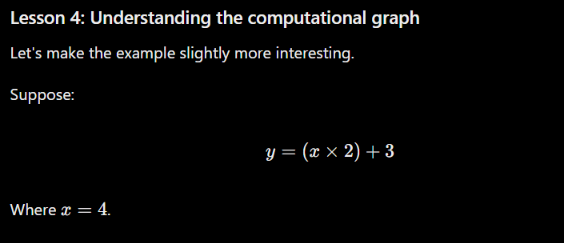

In [ ]:
x = torch.tensor(4.0, requires_grad=True)

a = x * 2
b = a + 3

print(a)
print(b)

tensor(8., grad_fn=<MulBackward0>)
tensor(11., grad_fn=<AddBackward0>)


In [ ]:
b.backward()
print(x.grad)

tensor(2.)


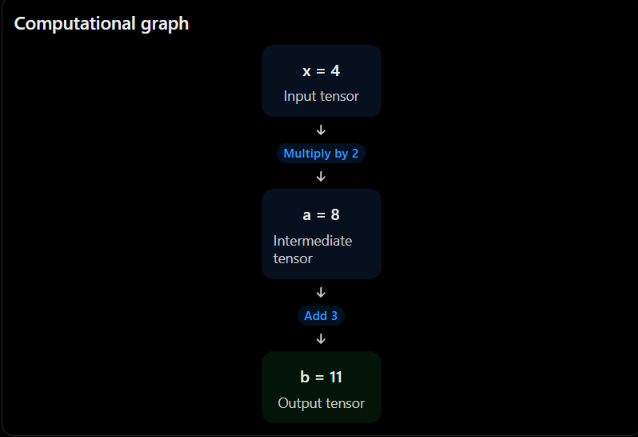

# **Some Properties of AutoGrad**

requires_grad : Whether the tensor participates in gradient tracking.

grad_fn : The operation that created a tensor in the computational graph.

grad : The gradient calculated for a leaf tensor.

In [ ]:
x = torch.tensor(4.0, requires_grad=True)

a = x * 2
b = a + 3

print(x.requires_grad)
print(a.requires_grad)
print(b.requires_grad)

print(x.grad_fn)
print(a.grad_fn)
print(b.grad_fn)

True
True
True
None


**Coding assignment**


Write this code yourself without copying the previous examples:


\[
y=3x^2+2x+5
\]

Take \(x=2\).

Your tasks:
1. Create x with requires_grad=True.
2. Calculate y.
3. Print y.
4. Call y.backward().
5. Print x.grad.
6. Calculate the derivative manually and compare it with PyTorch.

In [ ]:
x = torch.tensor(2.0 , requires_grad= True)

y = 3 * (x ** 2) + 2 * x + 5

print(y)
y.backward()
print(x.grad)

tensor(21., grad_fn=<AddBackward0>)
tensor(14.)


# **Leaf tensors**

A leaf tensor is generally a tensor that you create directly, rather than obtaining it as the result of an operation tracked by Autograd.

In [ ]:
x = torch.tensor(3.0, requires_grad=True)

print(x.is_leaf)
print(x.grad_fn)

True
None


Why?
- x.is_leaf is True because you created it directly.
- x.grad_fn is None because no tracked operation created it.

In [ ]:
x = torch.tensor(3.0, requires_grad=True)

y = x * 2
z = y + 5

print(y.is_leaf)
print(z.is_leaf)

print(y.grad_fn)
print(z.grad_fn)

False
False


Why?
- y was created through multiplication.
- z was created through addition.
Therefore, they are non-leaf tensors.

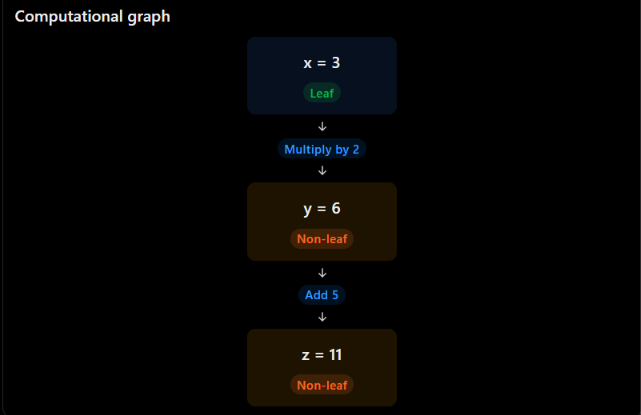

In [ ]:
x = torch.tensor(5.0 , requires_grad=True)

y = x * 2

z = y + 10

y.backward()


print(y)
print(x.grad)
print(y.grad) # -> Returns None

tensor(10., grad_fn=<MulBackward0>)
tensor(2.)
None


/tmp/ipykernel_2674/2077053922.py:12: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at /__w/pytorch/pytorch/build/aten/src/ATen/core/TensorBody.h:488.)
  print(y.grad)


By default, PyTorch retains gradients for leaf tensors, not non-leaf tensors.

It still calculates intermediate gradients during backpropagation, but doesn't retain them in .grad unless requested.

**retain_grad()**


If you also want to access the gradient of a non-leaf tensor, use:

In [ ]:
x = torch.tensor(5.0 , requires_grad=True)

y = x * 2

z = y + 10

y.retain_grad()

y.backward()


print(y)
print(x.grad)
print(y.grad)

tensor(10., grad_fn=<MulBackward0>)
tensor(2.)
tensor(1.)


**detach()**

creates a new tensor that is disconnected from the current computational graph.

In [ ]:
x = torch.tensor(3.0, requires_grad=True)

y = x * 2

z = y.detach()

print(z)
print(z.requires_grad)

tensor(6.)
False


**detach() disconnects a particular tensor from its existing computational graph.**

In [ ]:
from sklearn.datasets import make_regression

In [ ]:
x,y=make_regression(n_features=3,n_samples=1000,n_targets=1,noise=0.3)

In [ ]:
from sklearn.model_selection import train_test_split

X_train,x_test,Y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

In [ ]:
print(x.shape)
print(y.shape)
print(X_train.shape)

(1000, 3)
(1000,)
(700, 3)


In [ ]:
class GradientDescent:
  def __init__(self,lr=0.001,epoch=10):
    self.m=None
    self.b=0.0

    self.lr=lr
    self.epoch=epoch

  def fit(self,n_x,n_y):

    x = torch.tensor(n_x, dtype=torch.float32)
    y = torch.tensor(n_y, dtype=torch.float32)

    self.m=torch.rand(x.shape[1],requires_grad=True)
    self.b=torch.rand(1,requires_grad=True)

    for i in range(self.epoch):

      for i in range(x.shape[0]):
        x_i=x[i]
        y_i=y[i]

        y_hat= torch.sum(self.m * x_i) + self.b


        loss = (y_hat - y_i) ** 2
        loss.backward()

        with torch.no_grad():
          self.m -= self.lr * self.m.grad
          self.b -= self.lr * self.b.grad

                        # Clear gradients
        self.m.grad = None
        self.b.grad = None

    return self

  def predict(self,n_x):

    x = torch.tensor(n_x, dtype=torch.float32)

    with torch.no_grad():
      prediction = torch.matmul(x,self.m) + self.b
    return prediction


In [ ]:
import numpy as np
gd=GradientDescent()

gd.fit(X_train,Y_train)

In [ ]:
gd.predict(x_test)

tensor([-4.4544e+01, -8.5613e+01, -1.3712e+00,  5.5752e+01,  7.2079e+00,
        -2.4750e+01,  1.0818e+02,  1.9286e+02, -4.3583e+01, -1.3289e+02,
        -1.0953e+02,  4.8038e+01, -1.5650e+02,  2.2884e+02, -2.0593e+00,
         2.0919e+01, -4.0234e+01, -2.3993e+02, -6.6210e+01,  8.7836e+01,
        -2.9652e+02,  1.1961e+02, -7.3426e+01, -7.8403e+01,  9.9479e+01,
        -7.4670e+01, -5.7007e+01, -9.1201e+01,  1.4078e+02,  4.7192e+01,
         5.3041e+01, -2.9260e+02, -7.2270e+01, -8.8097e+00,  1.4030e+01,
         1.1439e+02, -2.9337e+02, -7.3672e-01,  1.0064e+02, -1.4842e+02,
         3.2844e+02, -2.8830e+02,  2.6807e+02, -1.2084e+02,  2.3894e+02,
         1.7616e+02,  9.1356e+01, -7.6473e+01, -2.2984e+02,  2.5388e+01,
        -5.3708e+01, -1.3513e+02, -1.4263e+01, -6.0686e+01,  1.1613e+02,
         1.8683e+02,  2.1718e+02,  5.5448e+01, -4.9925e+01, -8.6809e+01,
         3.2062e+01,  7.2569e+01,  1.2423e+02, -3.5570e+01, -7.9161e+01,
         1.4050e+01, -7.4366e+01, -9.1849e+01,  3.9

In [ ]:
from sklearn.linear_model import LinearRegression

lr=LinearRegression()

lr.fit(X_train,Y_train)
print(lr.predict(x_test))

[-4.45447673e+01 -8.56112227e+01 -1.35384732e+00  5.57624048e+01
  7.23000769e+00 -2.47536751e+01  1.08184121e+02  1.92858524e+02
 -4.35736730e+01 -1.32893720e+02 -1.09544005e+02  4.80453526e+01
 -1.56500017e+02  2.28871745e+02 -2.05107147e+00  2.09306290e+01
 -4.02280967e+01 -2.39940972e+02 -6.62160050e+01  8.78479456e+01
 -2.96526248e+02  1.19615259e+02 -7.34163321e+01 -7.84036676e+01
  9.94993419e+01 -7.46822495e+01 -5.69985769e+01 -9.11985407e+01
  1.40802564e+02  4.71850098e+01  5.30485363e+01 -2.92614019e+02
 -7.22605468e+01 -8.80923276e+00  1.40349838e+01  1.14393385e+02
 -2.93378944e+02 -7.38207974e-01  1.00657822e+02 -1.48423730e+02
  3.28461237e+02 -2.88300852e+02  2.68078925e+02 -1.20827326e+02
  2.38937401e+02  1.76176956e+02  9.13582579e+01 -7.64661783e+01
 -2.29827121e+02  2.53946860e+01 -5.37130233e+01 -1.35126819e+02
 -1.42568179e+01 -6.06733518e+01  1.16155015e+02  1.86843451e+02
  2.17194278e+02  5.54462456e+01 -4.99191435e+01 -8.68044353e+01
  3.20531319e+01  7.25733

# **WHY inplace operation is imp **